# AI for Trustworthy Decision Making — Stage 1
# Notebook B: Federated learning
## Federated Human Activity Recognition on WISDM Actitracker

**What the project is about.** A phone's accelerometer is enough to recognise what its owner is doing (walking, sitting, ...), but this sensor data is personal. In **federated learning (FL)** each client trains on its own data and only sends model weights to a server, which averages them (**FedAvg**); the raw data never leaves the client. We compare FL against normal **centralised** training (all data in one place) on the **WISDM Actitracker** dataset: 225 people, phone accelerometer at 20 Hz, 6 activities (Walking, Jogging, Stairs, Sitting, Standing, LyingDown).

**We reuse the course repository [AITDM_FLOWER_PROJECT_TUTORIAL](https://github.com/Chiru-CatalinMihail/AITDM_FLOWER_PROJECT_TUTORIAL) wherever possible:** `split_data.py` (clients + features), `centralised.py`, `run_seeds.py` + `fl_app/` (Flower, FedAvg), `summarize.py`, `error_analysis.py`. Our own code only reads the WISDM file, cuts it into windows and makes the tables/plots.

**Team:** Yannick Koning, Mihai-Dragos Toma

| Notebook | Owner | Content |
|---|---|---|
| **A – Data & centralised** | Mihai-Dragos Toma | dataset, preprocessing, 4 data variants, client splits, centralised MLP + Random Forest |
| **B – Federated** | Yannick Koning | FedAvg on the same splits, IID reference, FedProx / balanced loss, comparison with A, literature comparison |
| **C – Better features** (extra) | Mihai-Dragos Toma | 71 hand-crafted features on the same splits, centralised + FedAvg |

**How the two parts check each other:** B and C use A's client splits and the same 56 test users unchanged, and every federated run in B has a centralised counterpart in A trained on exactly the same data, so the results can be compared one to one.

**Research questions**
* **RQ1.** How close does FedAvg (5 clients) get to centralised training on the same data?
* **RQ2.** Does more training data or more features help, centralised and federated?
* **RQ3.** How well do the models work for **new users**, and for every client equally?

## Setup

In [1]:
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/AITDM_WISDM_stage1")   # shared by notebooks A and B
    REPO = Path("/content/AITDM_FLOWER_PROJECT_TUTORIAL")
    WORK = Path("/content/work")                                  # big temporary files (not in Drive)
else:  # local Jupyter
    PROJECT = Path(os.environ.get("AITDM_PROJECT", "AITDM_WISDM_stage1")).resolve()
    REPO = Path(os.environ.get("AITDM_REPO", PROJECT.parent / "AITDM_FLOWER_PROJECT_TUTORIAL")).resolve()
    WORK = PROJECT.parent / "work"
WORK.mkdir(parents=True, exist_ok=True)

# 1) the course repository
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Chiru-CatalinMihail/AITDM_FLOWER_PROJECT_TUTORIAL.git", str(REPO)], check=True)

# 2) its data/ and outputs/ folders live in Drive
for name in ["data", "outputs"]:
    (PROJECT / name).mkdir(parents=True, exist_ok=True)
    link = REPO / name
    if link.is_symlink() and os.path.realpath(link) != str((PROJECT / name).resolve()):
        link.unlink()                       # left over from another Drive folder: re-point it
    if not link.exists():
        link.symlink_to(PROJECT / name, target_is_directory=True)

# 3) install the packages (once)
try:
    import flwr, aitdm_fl
except ImportError:
    reqs = [l for l in (REPO / "requirements.txt").read_text().splitlines()
            if not l.startswith(("torch==", "torchvision=="))]
    (REPO / "requirements-colab.txt").write_text("\n".join(reqs))
    !pip install -q -r {REPO}/requirements-colab.txt
    !pip install -q -e {REPO}/fl_app

os.environ.setdefault("VIRTUAL_ENV", sys.prefix)  # the repo scripts expect an active environment
os.environ["CLIENT_CPUS"] = "1"                     # Flower: 2 clients train in parallel on Colab's 2 CPUs
os.chdir(REPO)
sys.path.insert(0, str(REPO / "experiments"))

PART = PROJECT / "data" / "partitions"
EXP = PROJECT / "outputs" / "experiments"
FIG = PROJECT / "figures"; FIG.mkdir(exist_ok=True)

# the 4 data variants (made in notebook A); every one uses the same 56 test users
VARIANTS = {
    "basic":        "12 features: mean/std/min/max of x, y, z",
    "rich":         "32 features: + magnitude and changes between readings",
    "overlap":      "12 features, 2x training windows (50 % overlap)",
    "rich_overlap": "32 features, 2x training windows",
}
import flwr, torch
print("flwr", flwr.__version__, "| torch", torch.__version__, "| results in", PROJECT)

missing = [p for p in ["user5_basic", "user5_rich", "user5_overlap", "user5_rich_overlap", "iid5_basic"]
           if not (PART / p / "meta.json").exists()]
assert not missing, f"Run notebook A first: missing client splits {missing}"

Mounted at /content/drive
flwr 1.41.0 | torch 2.14.1+cpu | results in /content/drive/MyDrive/AITDM_WISDM_stage1


## 1. How federated learning works here (FedAvg)

1. The server sends the same starting model to all 5 clients.
2. Each client trains it **only on its own data** for 3 epochs.
3. Each client sends back **only the model weights**, never the data.
4. The server **averages** the weights, weighted by how much data each client has. Example: one weight is 0.2 at client A (1,000 windows) and 0.6 at client B (3,000 windows) → (1000·0.2 + 3000·0.6) / 4000 = **0.5**.
5. Repeat for **10 rounds**.

Same model as notebook A (`features → 256 → 128 → 6`), same learning rate and batch size. 10 rounds × 3 local epochs = the 30 epochs of the centralised runs. Flower's simulation runs the server and the 5 clients on one machine (`experiments/run_seeds.py`, seeds 1, 2, 3).

**The clients** (made in notebook A): every person belongs to exactly one client (non-IID); 56 other people form the test set, which only the server uses at the end.

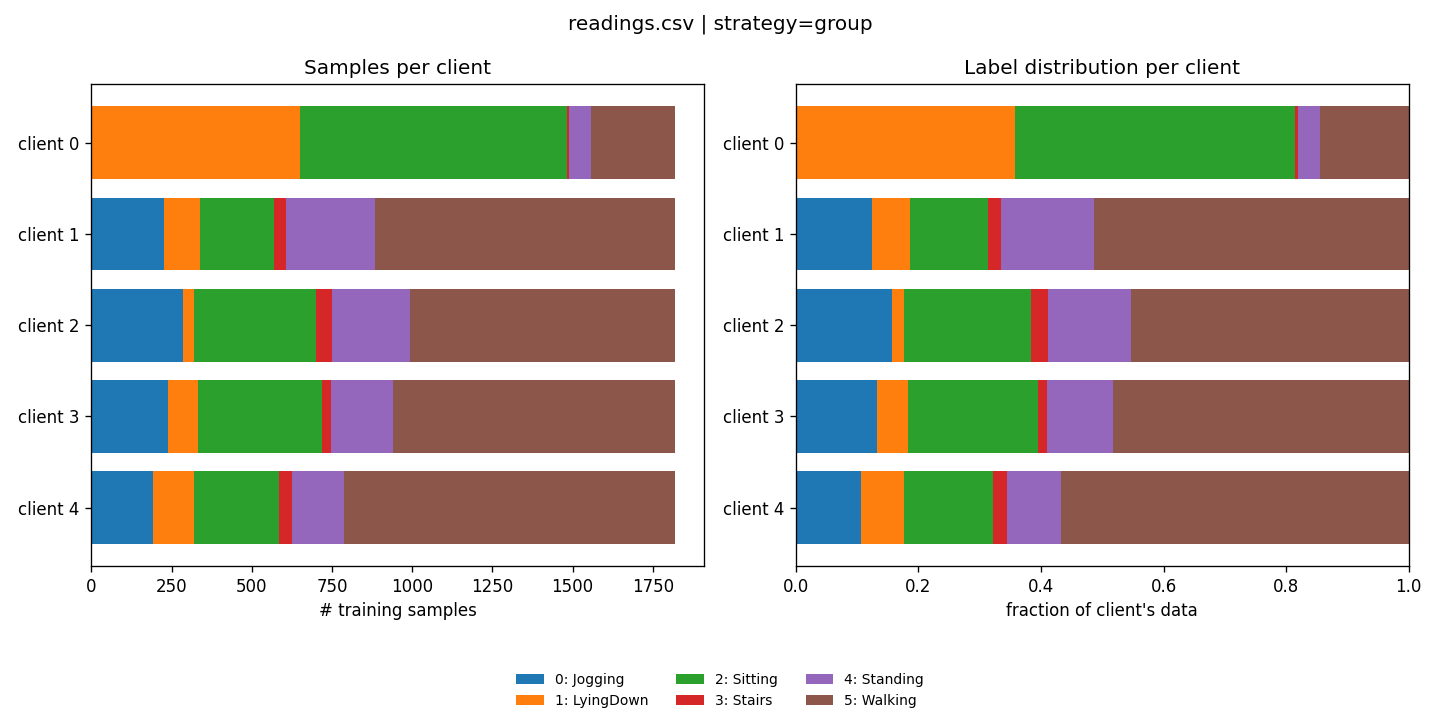

In [2]:
from IPython.display import Image, display
display(Image(str(PART / "user5_basic" / "label_distribution.png"), width=900))

## 2. FedAvg on the 4 data variants

One experiment per data variant of notebook A, so every federated result has a centralised counterpart.

In [3]:
FL = "num-server-rounds=10 local-epochs=3"
for v in VARIANTS:
    print(f"===== fedavg-{v} =====", flush=True)
    !python experiments/run_seeds.py --partitions {PART}/user5_{v} --seeds 1 2 3 --name fedavg-{v} --config "{FL} strategy='fedavg'" < /dev/null
!bash scripts/stop_flower.sh

===== fedavg-basic =====
>>> fedavg-basic seed 1
>>> fedavg-basic seed 2
>>> fedavg-basic seed 3

fedavg-basic (3 seeds, mean +- std)
  val   acc. 0.780 ± 0.006, bal. acc. 0.606 ± 0.009, macro-F1 0.613 ± 0.009
  test  acc. 0.780 ± 0.008, bal. acc. 0.570 ± 0.025, macro-F1 0.540 ± 0.029
  val per client: 0: 0.521 ± 0.010, 1: 0.793 ± 0.031, 2: 0.815 ± 0.017, 3: 0.889 ± 0.008, 4: 0.883 ± 0.018
===== fedavg-rich =====
>>> fedavg-rich seed 1
>>> fedavg-rich seed 2
>>> fedavg-rich seed 3

fedavg-rich (3 seeds, mean +- std)
  val   acc. 0.789 ± 0.002, bal. acc. 0.625 ± 0.012, macro-F1 0.627 ± 0.020
  test  acc. 0.791 ± 0.003, bal. acc. 0.587 ± 0.010, macro-F1 0.548 ± 0.014
  val per client: 0: 0.532 ± 0.002, 1: 0.832 ± 0.005, 2: 0.827 ± 0.002, 3: 0.897 ± 0.009, 4: 0.856 ± 0.006
===== fedavg-overlap =====
>>> fedavg-overlap seed 1
>>> fedavg-overlap seed 2
>>> fedavg-overlap seed 3

fedavg-overlap (3 seeds, mean +- std)
  val   acc. 0.805 ± 0.004, bal. acc. 0.651 ± 0.023, macro-F1 0.659 ± 0.021

## 3. IID reference

The same FedAvg on the **IID** split (basic data, windows dealt to the clients at random, so every client has the same mix of activities). Unrealistic, but it separates the cost of *federated training* from the cost of *non-IID data*.

In [4]:
!python experiments/run_seeds.py --partitions {PART}/iid5_basic --seeds 1 2 3 --name fedavg-iid-basic --config "{FL} strategy='fedavg'" < /dev/null
!bash scripts/stop_flower.sh

>>> fedavg-iid-basic seed 1
>>> fedavg-iid-basic seed 2
>>> fedavg-iid-basic seed 3

fedavg-iid-basic (3 seeds, mean +- std)
  val   acc. 0.865 ± 0.004, bal. acc. 0.798 ± 0.001, macro-F1 0.815 ± 0.003
  test  acc. 0.796 ± 0.004, bal. acc. 0.653 ± 0.007, macro-F1 0.624 ± 0.010
  val per client: 0: 0.842 ± 0.007, 1: 0.885 ± 0.003, 2: 0.867 ± 0.006, 3: 0.862 ± 0.010, 4: 0.869 ± 0.005
Stopped flower-superlink
Stopped flower-superexec


## 4. First steps against the non-IID problems (preview of Stage 2)

Both are options of the repository's Flower app, used on the best data variant (`rich_overlap`):
* **FedProx** (`strategy='fedprox'`, μ = 0.1): each client's training is pulled back towards the global model, so clients with very different data drift less.
* **Balanced loss** (`loss-weighting='balanced'`): each client weights its loss by inverse class frequency, so rare activities count more.

In [5]:
!python experiments/run_seeds.py --partitions {PART}/user5_rich_overlap --seeds 1 2 3 --name fedprox-rich_overlap --config "{FL} strategy='fedprox' proximal-mu=0.1" < /dev/null
!python experiments/run_seeds.py --partitions {PART}/user5_rich_overlap --seeds 1 2 3 --name fedavg-balanced-rich_overlap --config "{FL} strategy='fedavg' loss-weighting='balanced'" < /dev/null
!bash scripts/stop_flower.sh

>>> fedprox-rich_overlap seed 1
>>> fedprox-rich_overlap seed 2
>>> fedprox-rich_overlap seed 3

fedprox-rich_overlap (3 seeds, mean +- std)
  val   acc. 0.811 ± 0.005, bal. acc. 0.615 ± 0.012, macro-F1 0.623 ± 0.010
  test  acc. 0.810 ± 0.003, bal. acc. 0.587 ± 0.012, macro-F1 0.558 ± 0.013
  val per client: 0: 0.604 ± 0.003, 1: 0.869 ± 0.004, 2: 0.796 ± 0.018, 3: 0.889 ± 0.006, 4: 0.896 ± 0.013
>>> fedavg-balanced-rich_overlap seed 1
>>> fedavg-balanced-rich_overlap seed 2
>>> fedavg-balanced-rich_overlap seed 3

fedavg-balanced-rich_overlap (3 seeds, mean +- std)
  val   acc. 0.770 ± 0.017, bal. acc. 0.701 ± 0.022, macro-F1 0.645 ± 0.012
  test  acc. 0.750 ± 0.010, bal. acc. 0.656 ± 0.013, macro-F1 0.580 ± 0.008
  val per client: 0: 0.500 ± 0.025, 1: 0.809 ± 0.035, 2: 0.804 ± 0.018, 3: 0.874 ± 0.011, 4: 0.861 ± 0.018
Stopped flower-superlink
Stopped flower-superexec


## 5. Results

### 5.1 Centralised (notebook A) vs. federated, on the same data

* *Val* = the clients' validation data (people seen in training).
* *Test* = the 56 held-out users (people never seen): **the number that matters**.
* *Worst client* = the lowest per-client validation accuracy (a simple fairness number).

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from summarize import summarize_experiment

def ms(stat):
    return f"{stat['mean']:.3f} ± {stat['std']:.3f}"

runs = [(f"central-{v}", "centralised", v) for v in VARIANTS] + \
       [(f"fedavg-{v}", "FedAvg", v) for v in VARIANTS] + \
       [("fedavg-iid-basic", "FedAvg, IID clients", "basic"),
        ("fedprox-rich_overlap", "FedProx", "rich_overlap"),
        ("fedavg-balanced-rich_overlap", "FedAvg + balanced loss", "rich_overlap")]
S, rows = {}, []
for exp_name, method, v in runs:
    if not (EXP / exp_name).exists():
        print("missing:", exp_name, "(notebook A not run?)"); continue
    s = S[exp_name] = summarize_experiment(EXP / exp_name, quiet=True)
    rows.append({"Method": method, "Data variant": v,
                 "Val acc.": ms(s["val"]["accuracy"]), "Worst client val acc.": ms(s["val_worst_client_accuracy"]),
                 "Test acc.": ms(s["test"]["accuracy"]), "Test bal. acc.": ms(s["test"]["balanced_accuracy"]),
                 "Test macro-F1": ms(s["test"]["f1_macro"])})
results = pd.DataFrame(rows)
(PROJECT / "results").mkdir(exist_ok=True)
results.to_csv(PROJECT / "results" / "all_results.csv", index=False)
results

,Method,Data variant,Val acc.,Worst client val acc.,Test acc.,Test bal. acc.,Test macro-F1
0,centralised,basic,0.901 ± 0.003,0.865 ± 0.017,0.796 ± 0.001,0.641 ± 0.004,0.621 ± 0.002
1,centralised,rich,0.913 ± 0.005,0.893 ± 0.005,0.798 ± 0.009,0.669 ± 0.014,0.654 ± 0.013
2,centralised,overlap,0.934 ± 0.003,0.909 ± 0.007,0.787 ± 0.015,0.639 ± 0.014,0.623 ± 0.015
3,centralised,rich_overlap,0.944 ± 0.003,0.920 ± 0.006,0.801 ± 0.008,0.678 ± 0.007,0.666 ± 0.005
4,FedAvg,basic,0.780 ± 0.006,0.521 ± 0.010,0.780 ± 0.008,0.570 ± 0.025,0.540 ± 0.029
5,FedAvg,rich,0.789 ± 0.002,0.532 ± 0.002,0.791 ± 0.003,0.587 ± 0.010,0.548 ± 0.014
6,FedAvg,overlap,0.805 ± 0.004,0.558 ± 0.015,0.778 ± 0.011,0.563 ± 0.016,0.541 ± 0.010
7,FedAvg,rich_overlap,0.810 ± 0.005,0.550 ± 0.008,0.797 ± 0.010,0.605 ± 0.019,0.584 ± 0.021
8,"FedAvg, IID clients",basic,0.865 ± 0.004,0.842 ± 0.007,0.796 ± 0.004,0.653 ± 0.007,0.624 ± 0.010
9,FedProx,rich_overlap,0.811 ± 0.005,0.604 ± 0.003,0.810 ± 0.003,0.587 ± 0.012,0.558 ± 0.013


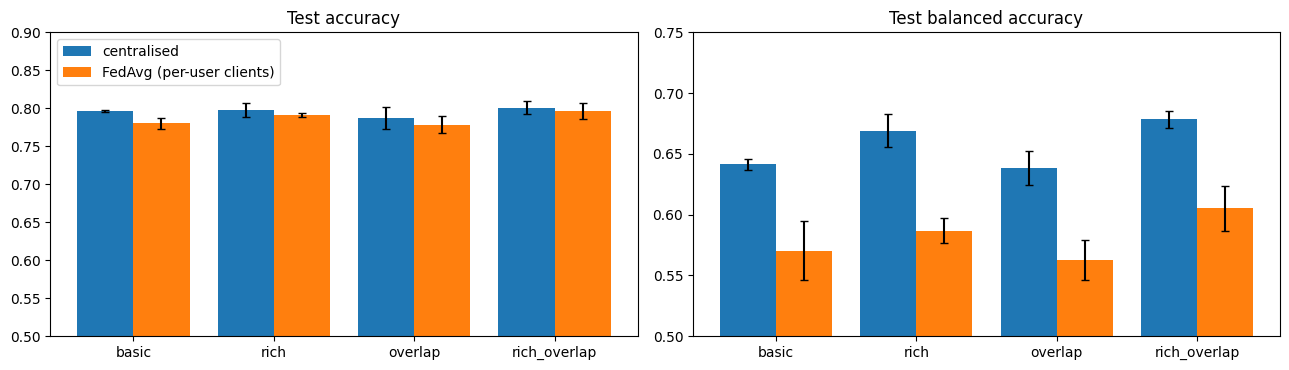

In [7]:
# centralised vs FedAvg per data variant (test = new users)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(len(VARIANTS))
for ax, metric, title in [(axes[0], "accuracy", "Test accuracy"), (axes[1], "balanced_accuracy", "Test balanced accuracy")]:
    for k, (prefix, label) in enumerate([("central", "centralised"), ("fedavg", "FedAvg (per-user clients)")]):
        vals = [S[f"{prefix}-{v}"]["test"][metric] for v in VARIANTS]
        ax.bar(x + (k - 0.5) * 0.4, [m["mean"] for m in vals], 0.4, yerr=[m["std"] for m in vals], capsize=3, label=label)
    ax.set_xticks(x, list(VARIANTS)); ax.set_title(title)
    ax.set_ylim(0.5, 0.9 if metric == "accuracy" else 0.75)
axes[0].legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "central_vs_fedavg.png", dpi=150); plt.show()

### 5.2 Learning curves

After every round each client evaluates the new global model on its validation data; the server records the average (`metrics.json`). The dashed lines are the centralised models after 30 epochs.

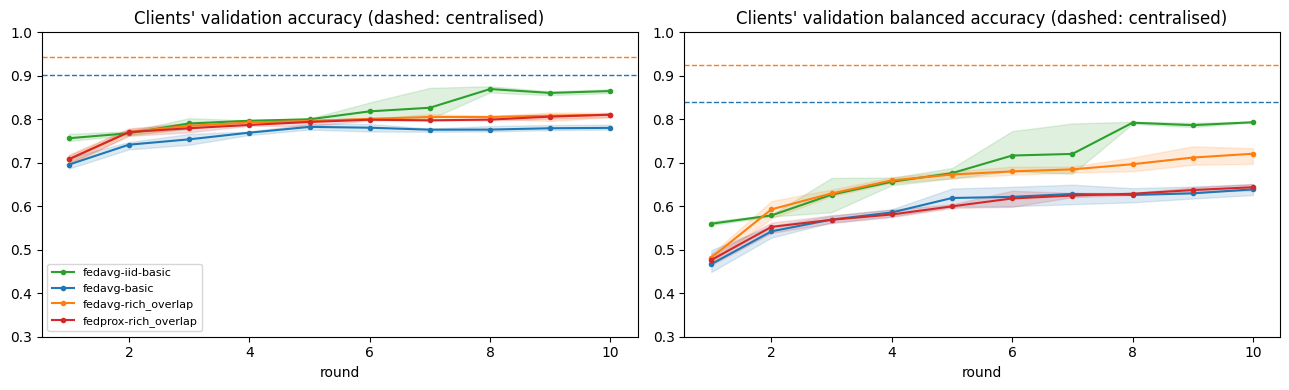

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in [("fedavg-iid-basic", "tab:green"), ("fedavg-basic", "tab:blue"),
                    ("fedavg-rich_overlap", "tab:orange"), ("fedprox-rich_overlap", "tab:red")]:
    runs_ = [json.loads(f.read_text())["evaluate_metrics_clientapp"] for f in sorted((EXP / name).glob("seed*/metrics.json"))]
    for metric, ax in zip(["eval_acc", "eval_bal_acc"], axes):
        curves = np.array([[r[k][metric] for k in sorted(r, key=int)] for r in runs_])   # seeds x rounds
        rounds = np.arange(1, curves.shape[1] + 1)
        ax.plot(rounds, curves.mean(0), "-o", ms=3, color=color, label=name)
        ax.fill_between(rounds, curves.min(0), curves.max(0), color=color, alpha=0.15)
for ax, key, title in zip(axes, ["accuracy", "balanced_accuracy"], ["accuracy", "balanced accuracy"]):
    for v, color in [("basic", "tab:blue"), ("rich_overlap", "tab:orange")]:
        ax.axhline(S[f"central-{v}"]["val"][key]["mean"], ls="--", color=color, lw=1)
    ax.set(xlabel="round", title=f"Clients' validation {title} (dashed: centralised)", ylim=(0.3, 1))
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "learning_curves.png", dpi=150); plt.show()

### 5.3 Per-client results (fairness)

Every model evaluated on each client's own validation data (`rich_overlap` split). Does the federated model work equally well for every client, or only on average?

In [9]:
meta = json.loads((PART / "user5_rich_overlap" / "meta.json").read_text())
rows = []
for c in meta["clients"]:
    i = str(c["client"]); counts = dict(zip(meta["class_names"], c["train_class_counts"]))
    row = {"client": i, "train windows": c["train"], "most common activity": max(counts, key=counts.get)}
    for exp_name, label in [("central-rich_overlap", "centralised"), ("fedavg-rich_overlap", "FedAvg"),
                            ("fedprox-rich_overlap", "FedProx"), ("fedavg-balanced-rich_overlap", "FedAvg+balanced")]:
        row[f"{label} acc."] = round(S[exp_name]["val_per_client"][i]["accuracy"]["mean"], 3)
    rows.append(row)
per_client = pd.DataFrame(rows)
per_client.to_csv(PROJECT / "results" / "per_client.csv", index=False)
per_client

,client,train windows,most common activity,centralised acc.,FedAvg acc.,FedProx acc.,FedAvg+balanced acc.
0,0,3596,Sitting,0.920,0.550,0.604,0.500
1,1,3596,Walking,0.957,0.868,0.869,0.809
2,2,3596,Walking,0.928,0.799,0.796,0.804
3,3,3596,Walking,0.952,0.893,0.889,0.874
4,4,3596,Walking,0.966,0.941,0.896,0.861


### 5.4 Where does FedAvg make mistakes on new users?

Repository's `error_analysis.py` (FedAvg, `rich_overlap`, seed 1). Compare with the centralised confusion matrix at the end of notebook A.

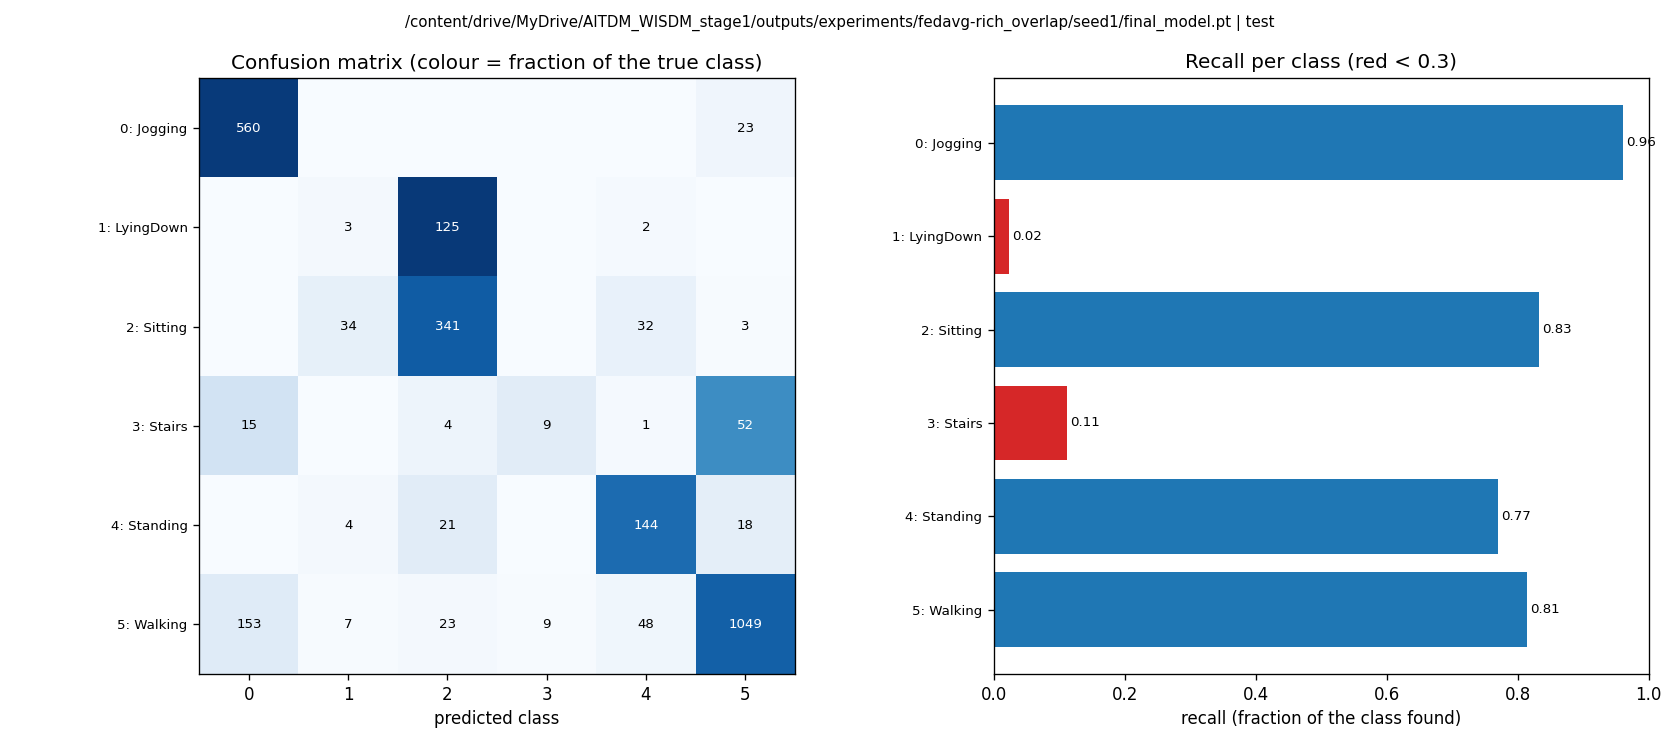

In [10]:
run = EXP / "fedavg-rich_overlap" / "seed1"
!python explainability/error_analysis.py --run {run} --data test > /dev/null
display(Image(str(run / "errors_test.png"), width=850))

### 5.5 Comparison with the literature (state of the art)

| Work | Data | Evaluation | Model | Accuracy |
|---|---|---|---|---|
| Kwapisz et al. (2011) | WISDM lab version (36 people) | 10-fold cross-validation over windows | MLP on statistical features | 91.7 % |
| Alsheikh et al. (2016) | **WISDM Actitracker** | not user-independent as far as stated; multi-class "accuracy" = mean of per-class one-vs-rest accuracies (counts true negatives) | deep belief network | 98.2 %* |
| Peppas et al. (2020) | **WISDM Actitracker** | test on Actitracker (protocol not detailed) | CNN + statistical features | 79.1 % |
| **Ours, centralised MLP** | **WISDM Actitracker** | known users (validation) / **new users (test)** | MLP, `rich_overlap` | 0.944 / **0.801** |
| **Ours, FedAvg (5 clients)** | **WISDM Actitracker** | known users / **new users** | same MLP, federated, `rich_overlap` | 0.810 / **0.797** |
| **Ours, centralised MLP** | **WISDM Actitracker** | known users / **new users** | MLP, 71 hand-crafted features (notebook C) | 0.938 / **0.828** |
| **Ours, FedAvg (5 clients)** | **WISDM Actitracker** | known users / **new users** | same MLP, federated, hand-crafted features | 0.866 / **0.829** |

**How to read it:** published numbers are not directly comparable, because the evaluation protocol matters a lot. When the same people appear in training and test (as in most cross-validation over windows), accuracies of 90–98 % are typical, and our models reach a similar range on *known* users (0.94 centralised). On *new* users, which is what we measure on the test set, we get 0.80–0.83. That is in line with the 79.1 % Peppas et al. report on Actitracker, even though their model is a CNN and our federated model never saw anyone's raw data. Our point is not to beat these numbers, but to measure the cost of federated learning under a strict, realistic protocol (unseen users).

\* Alsheikh et al. define multi-class accuracy as the average over the classes of (TP + TN) / (TP + TN + FP + FN). Because every class also counts its true negatives, this is much higher than ordinary accuracy (a model that is right 80 % of the time can score above 90 % on it), so the 98.2 % is not comparable with the other rows. Peppas et al. report 79.12 % on Actitracker in their abstract.

## 6. Discussion

> All numbers: mean of seeds 1–3, from the tables above.

**RQ1 – Federated vs. centralised.**
* **IID clients:** FedAvg ≈ centralised on the new users (test accuracy 0.80 vs. 0.80, balanced accuracy 0.65 vs. 0.64). Federated training itself costs almost nothing.
* **Realistic per-user clients (non-IID):** test accuracy stays close (0.78 vs. 0.80), but **balanced accuracy drops from 0.64 to 0.57**. The loss is on the rare activities (LyingDown, Stairs), which plain accuracy hides. The confusion matrix shows FedAvg confusing LyingDown with Sitting and Stairs with Walking.
* So the problem is the **non-IID data**, not federated learning as such. The learning curves show the same: the IID curve gets close to the centralised line, the per-user curves stay below.

**RQ2 – More data and more features.**
* Together they help both settings: centralised balanced accuracy 0.64 → 0.68, FedAvg 0.57 → 0.61. With `rich_overlap`, FedAvg reaches about the same test accuracy as centralised (0.80).
* Alone, more features help the centralised model (0.64 → 0.67) but more data does not (0.64). For FedAvg neither helps on its own (`rich` 0.59, `overlap` 0.56 vs. `basic` 0.57, within the seed-to-seed noise).
* Validation accuracy rises much more than test accuracy (centralised 0.90 → 0.94 vs. test 0.80 → 0.80). The model learns the *known* people better, but that barely transfers to *new* people.
* The Random Forest is the best centralised model on new users (balanced accuracy 0.69 with `rich_overlap`), but it is a centralised-only reference: decision trees cannot be averaged by FedAvg.

**RQ3 – New users and fairness across clients.**
* **New users are the hardest part:** the best centralised MLP reaches 0.94 on known users but 0.80 on new ones. People move and carry their phones differently (as in Weiss & Lockhart, 2012).
* **One client is left behind:** client 0, the only client where Sitting is the most common activity, reaches 0.92 validation accuracy with the centralised model but only ≈ 0.55 with FedAvg, while clients 3–4 stay at ≈ 0.90. The averaged model fits the majority (Walking-heavy clients).

**First steps against these problems (preview of Stage 2).**
* **FedProx** raises the weakest client from 0.55 to 0.60 without hurting test accuracy (0.81), but balanced accuracy drops slightly (0.61 → 0.59).
* **Balanced loss** gives the best federated balanced accuracy on new users (0.66, close to the 0.68 of the centralised MLP on the same data), but plain accuracy drops (0.80 → 0.75) and the weakest client gets even worse (0.50).
* No single option fixes everything: there are **trade-offs between overall accuracy, rare classes and the weakest client**. Measuring and balancing these trade-offs is the subject of Stage 2.

### Limitations
* **Simple features:** mean/std/min/max ignore how the signal changes over time. Notebook C shows that better hand-crafted features already help (centralised balanced accuracy 0.73, worst FedAvg client 0.80); a 1D-CNN on the raw windows could do better still.
* **Data quality:** most LyingDown windows come from one person whose phone records no gravity, so models can learn this quirk instead of the activity.
* **Optimistic validation:** validation windows come from the same people as training windows (and overlap with them in the `overlap` variants). Only the test set measures new people.
* **Simulation:** 5 clients that each group many people (cross-silo). Real phones would be thousands of small clients that are not always online.
* **No privacy guarantee yet:** the weights the clients send can still leak information about their data.

### Plan for Stage 2
| Dimension | What we saw | What we will try (all built into the repository) | How we measure it |
|---|---|---|---|
| **Fairness** | client 0 at ≈ 0.55; rare classes missed | FedProx (different μ), q-FedAvg, balanced loss | worst-client accuracy, per-class recall |
| **Privacy** | weights shared unprotected | differential privacy (`dp-noise-multiplier`, the repo reports ε) | accuracy vs. ε |
| **Robustness** | one unusual client already pulls the model | FedMedian / Krum with simulated attackers | accuracy with 0, 1, 2 attackers |
| **Interpretability** | possible gravity shortcut for LyingDown | `explainability/feature_importance.py` | which features the models use |